In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_ref = os.path.join(pth_data, 'ref', 'CELLxGENE')
pth_3ca = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'pancan')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth_data, 'results', 'emtarget', 'identify')
pth_fig = os.path.join(pth, 'figures', 'emtarget')

In [ ]:
fn = os.path.join(pth_data, 'summary.csv')
df_summary = pd.read_csv(fn, index_col = 0)
labels_dict = df_summary.Module.dropna().to_dict()
labels_dict

{'GSE162534': 'Gast', 'GSE229103': 'pSom', 'rRNAModifications': 'Crest'}

In [4]:
# load 3CA signatures
adata = sc.read_h5ad(os.path.join(pth_3ca, 'signatures.h5ad'))
adata

AnnData object with n_obs × n_vars = 1406087 × 245
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [5]:
# load CZ CELLxGENE gene expression (pseudobulk)
fn = os.path.join(pth_ref, 'pbulk.csv')
df = pd.read_csv(fn, index_col = [0, 1])
df = df.sub(df.mean(axis = 1), axis = 0)

In [6]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# module signatures — normal tissues / cell types
df_normal = pd.DataFrame(index = df.index)
for src, df_src in feat_dict.items():
    if src != 'union':
        g = df_src.hsapiens.drop_duplicates()
        g = g.loc[g.isin(df.columns)].copy()
        df_normal[src] = df[g].mean(axis = 1)
        print(src, g.size, df.shape[1])
df_normal.to_csv(os.path.join(pth_out, 'normal.csv'))

GSE162534 81 238
GSE229103 98 238
rRNAModifications 103 238


In [7]:
# module signatures — 3CA diseases
src = df_normal.columns.values
df_3ca = (adata.obs
          .groupby('Disease', observed = True)
          [src].mean())
df_3ca.to_csv(os.path.join(pth_out, 'malignant.csv'))

In [8]:
# tidy results table
df_normal['source'] = 'Normal'
df_3ca['source'] = 'Cancer'
df_res = (pd.concat((df_normal, df_3ca), axis = 0)
          .melt(id_vars = 'source',
                value_vars = src,
                var_name = 'module',
                value_name = 'signature'))

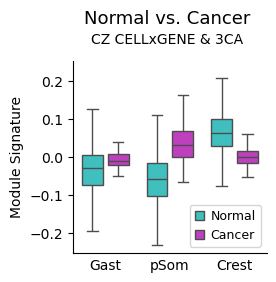

In [9]:
# plot signatures — normal vs. cancer
fig, ax = plt.subplots(1, 1, figsize = (2.5, 2.5))
c_dict = {'Normal' : 'cyan', 'Cancer' : 'magenta'}
sns.boxplot(df_res, x = 'module',
            y = 'signature',
            hue = 'source', 
            palette = c_dict,
            showfliers = False,
            saturation = .5,
            gap = .2, ax = ax)
ylim = max(abs(np.asarray(ax.get_ylim())))
ax.set_ylim(-ylim, ylim)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels,
          loc = 'lower right',
          fontsize = 9,
          handlelength = .75,
          handletextpad = .5)
ax.set_xticks(ax.get_xticks(),
              [labels_dict[lbl.get_text()] for
               lbl in ax.get_xticklabels()])
ax.tick_params('x', size = 0); ax.set_xlabel('')
ax.set_ylabel('Module Signature')
fig.suptitle('Normal vs. Cancer', size = 13, y = 1.085)
fig.text(.5, .95, 'CZ CELLxGENE & 3CA', ha = 'center')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
fn = os.path.join(pth_fig, 'identify.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [12]:
# statistical tests
for name in src:
    res = ttest_ind(df_normal[name],
                    df_3ca[name],
                    equal_var = False,
                    alternative = 'less')
    print(name, 'p =', res.pvalue)
    

GSE162534 p = 0.034934996447089715
GSE229103 p = 7.248830196345611e-12
rRNAModifications p = 0.9999982983841114
